# ДЗ №2. Семантическая сегментация кожных поражений

**Источник данных:** [Dataset Ninja — Skin Cancer: HAM10000](https://datasetninja.com/skin-cancer-ham10000) (версия с масками Supervisely).

**Задача:** самостоятельно реализовать **одну** компактную архитектуру сегментации (encoder–decoder со skip-связью), обучить её как минимум **дважды** при изменении одного параметра и сравнить результаты.

В блокноте уже подготовлены чтение изображений и разметки, формирование фиксированных выборок, `Dataset`, `DataLoader` и визуальная проверка данных. **Реализацию архитектуры, обучение, вычисление метрики и экспериментальное сравнение выполняете самостоятельно.**

Полное условие и критерии: [страница домашнего задания](https://ai-mai-307.github.io/ml-dl-course-site/courses/deep-learning/2026-fall/assignments/hw-02/).

## 1. Скачивание и распаковка датасета

1. Откройте [Skin Cancer: HAM10000 — Dataset Ninja](https://datasetninja.com/skin-cancer-ham10000), выберите **Download** для **полного архива Supervisely** (около 2,6 ГБ). Обычный HAM10000 без аннотаций и **Download Sample** не подходят для итоговых экспериментов.
2. Распакуйте архив в каталог `data/` рядом с `solution.ipynb`. Пример из PowerShell в папке с ноутбуком:

   ```powershell
   New-Item -ItemType Directory -Force data
   tar -xf "ИМЯ_СКАЧАННОГО_АРХИВА.tar" -C data
   ```

   Не переименовывайте файлы внутри архива. Если после распаковки возникли дополнительные вложенные папки, изменять их структуру не нужно: следующий код рекурсивно найдёт `img/` и `ann/`.
3. Установите зависимости в используемое Python-окружение (если их ещё нет):

   ```powershell
   python -m pip install torch numpy pandas pillow matplotlib scikit-learn
   ```

Файл `dataset_meta_comp.csv` **не нужен**: таблица `ds_df` и разбиение создаются автоматически. При запуске Jupyter текущая рабочая папка должна совпадать с папкой, где лежат `solution.ipynb` и `data/`.

## 2. Импорт библиотек и фиксированные параметры

In [25]:
import base64
import io
import json
import random
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset


def set_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


SEED = 42
set_random_seeds(SEED)

DATA_DIR = Path("data")
IMAGE_SIZE = (96, 128)       # (H, W); фиксируется для обоих экспериментов
MAX_TRAIN_PER_CLASS = 120    # фиксируется для обоих экспериментов
MAX_VAL_PER_CLASS = 30      # фиксируется для обоих экспериментов
BATCH_SIZE = 4              # одинаковый на CPU и GPU
NUM_WORKERS = 0             # без дополнительных процессов (удобно для Windows)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MIN_EPOCHS = 8              # минимальное число эпох для КАЖДОГО запуска
M_MIN = 0.05               # минимальная val mIoU для базовой модели
MIN_TRAIN_LOSS_DROP = 0.20 # средний train loss: последние 3 эпохи против первых 3

print(f"PyTorch {torch.__version__} | Устройство: {DEVICE}")
print(f"Папка данных: {DATA_DIR.resolve()}")

PyTorch 2.14.1+cu132 | Устройство: cuda
Папка данных: D:\STUDY IDIOT\PYTHON\Technolgy of AI\AI Technology HW 1\2\data


## 3. Таблица изображений и метаданных

В архиве Dataset Ninja отсутствуют собственные `train/val`-метки и файл метаданных. Здесь мы находим JSON-аннотации в формате Supervisely, восстанавливаем имена файлов и список классов.

Два изображения без bitmap-разметки исключаются. Валидация построена как **воспроизводимое стратифицированное разбиение по классу изображения**.

In [26]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Не найдена папка {DATA_DIR.resolve()}. Сначала распакуйте архив Dataset Ninja в data/."
    )

annotation_files = sorted(DATA_DIR.rglob("ann/*.json"))
if not annotation_files:
    raise FileNotFoundError(
        f"В {DATA_DIR.resolve()} не найдены ann/*.json. "
        "Проверьте, что скачан архив Supervisely (с аннотациями), а не исходный HAM10000."
    )

rows = []
ignored_without_bitmap = 0
missing_images = []
for ann_path in annotation_files:
    with ann_path.open("r", encoding="utf-8") as f:
        ann = json.load(f)

    objects = [obj for obj in ann.get("objects", []) if obj.get("bitmap")]
    if not objects:
        ignored_without_bitmap += 1
        continue

    # Имена файлов Supervisely: ISIC_....jpg и ISIC_....jpg.json
    img_name = ann_path.name.removesuffix(".json")
    img_path = ann_path.parent.parent / "img" / img_name
    if not img_path.is_file():
        missing_images.append(str(img_path))
        continue

    class_titles = [obj["classTitle"] for obj in objects]
    class_name = Counter(class_titles).most_common(1)[0][0]
    rows.append({
        "img_name": img_name,
        "ann_name": ann_path.name,
        "class_name": class_name,
        "img_path": img_path,
        "ann_path": ann_path,
    })

if missing_images:
    raise FileNotFoundError(
        f"Для {len(missing_images)} аннотаций не найдены изображения. "
        f"Первое: {missing_images[0]}"
    )
if not rows:
    raise ValueError("Не найдено ни одного изображения с bitmap-аннотацией.")

ds_df = pd.DataFrame(rows).sort_values("img_name").reset_index(drop=True)

# Порядок по алфавиту соответствует исходной таблице преподавателя:
# 1=actinic keratoses, 2=basal cell carcinoma, 3=benign keratosis-like lesions,
# 4=dermatofibroma, 5=melanocytic nevi, 6=melanoma, 7=vascular lesions.
CLASS_NAMES = sorted(ds_df["class_name"].unique(), key=str.casefold)
CLASS_TO_INDEX = {name: idx + 1 for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES) + 1  # ещё один класс — фон = 0

if NUM_CLASSES != 8:
    raise ValueError(
        f"Ожидались 7 диагностических классов и фон, получено: {CLASS_NAMES}. "
        "Если скачан только Sample, проверьте полный архив."
    )

ds_df["class_index"] = ds_df["class_name"].map(CLASS_TO_INDEX).astype(int)
print(f"Изображений с масками: {len(ds_df)}; без bitmap: {ignored_without_bitmap}")
print("Классы: 0 — фон")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} — {name}")
display(ds_df[["img_name", "class_name", "class_index"]].head())

Изображений с масками: 10013; без bitmap: 2
Классы: 0 — фон
  1 — actinic keratoses
  2 — basal cell carcinoma
  3 — benign keratosis-like lesions
  4 — dermatofibroma
  5 — melanocytic nevi
  6 — melanoma
  7 — vascular lesions


,img_name,class_name,class_index
0,ISIC_0024306.jpg,melanocytic nevi,5
1,ISIC_0024307.jpg,melanocytic nevi,5
2,ISIC_0024308.jpg,melanocytic nevi,5
3,ISIC_0024309.jpg,melanocytic nevi,5
4,ISIC_0024310.jpg,melanoma,6


In [27]:
train_df, val_df = train_test_split(
    ds_df,
    test_size=0.20,
    stratify=ds_df["class_index"],
    random_state=SEED,
)
train_df = train_df.copy().assign(split="train")
val_df = val_df.copy().assign(split="val")
ds_df = pd.concat([train_df, val_df], ignore_index=True)

assert set(train_df["img_path"]).isdisjoint(set(val_df["img_path"]))


def limit_per_class(frame, maximum):
    if maximum is None:
        return frame.sort_values("img_name").reset_index(drop=True)
    indices = []
    for _, group in frame.groupby("class_index"):
        n = min(len(group), maximum)
        indices.extend(group.sample(n=n, random_state=SEED).index.tolist())
    return frame.loc[indices].sort_values("img_name").reset_index(drop=True)


train_used = limit_per_class(train_df, MAX_TRAIN_PER_CLASS)
val_used = limit_per_class(val_df, MAX_VAL_PER_CLASS)
print(f"Train: {len(train_df)} всего, {len(train_used)} используются")
print(f"Val:   {len(val_df)} всего, {len(val_used)} используются")
print("Валидационные классы:", val_used["class_index"].value_counts().sort_index().to_dict())
assert val_used["class_index"].nunique() == NUM_CLASSES - 1, "В val представлены не все семь классов"
assert train_used["class_index"].nunique() == NUM_CLASSES - 1, "В train представлены не все семь классов"
assert set(train_used["img_path"]).isdisjoint(set(val_used["img_path"]))

Train: 8010 всего, 806 используются
Val:   2003 всего, 201 используются
Валидационные классы: {1: 30, 2: 30, 3: 30, 4: 23, 5: 30, 6: 30, 7: 28}


## 4. Преобразование Supervisely-масок и `Dataset`

Разметка хранится как `base64 → zlib → PNG` вместе со смещением `bitmap.origin`. Область объекта извлекается из **альфа-канала** PNG. Изображение масштабируется билинейно, маска — методом ближайшего соседа, чтобы индексы классов не смешивались.

`SkinCancerDataset[i]` возвращает тройку `(image, mask, class_index)`:

- `image`: `torch.float32`, форма `[3, H, W]`, нормировка в `[-1, 1]`;
- `mask`: `torch.int64`, форма `[H, W]`, метки `0..7` (`0` — фон);
- `class_index`: диагностический класс изображения (1–7).

Изображения и маски читаются **по требованию**: весь архив вряд ли поместится в оперативную память.

In [28]:
def decode_supervisely_bitmap_to_binary(mask_data_b64):
    raw = base64.b64decode(mask_data_b64)
    try:
        raw = zlib.decompress(raw)
    except zlib.error:
        # На случай, если данные уже содержат PNG без zlib-сжатия.
        pass
    with Image.open(io.BytesIO(raw)) as bitmap_image:
        rgba = np.asarray(bitmap_image.convert("RGBA"))
    return (rgba[..., 3] > 0).astype(np.uint8)


class SkinCancerDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size  # (H, W)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        h, w = self.image_size

        with Image.open(row["img_path"]) as img:
            img = img.convert("RGB")
            original_w, original_h = img.size
            img = img.resize((w, h), resample=Image.Resampling.BILINEAR)
            img_array = np.asarray(img).copy()

        image = torch.from_numpy(img_array).permute(2, 0, 1).float() / 255.0
        image = (image - 0.5) / 0.5

        # Сначала маска в исходном разрешении, потом NEAREST-resize.
        full_mask = np.zeros((original_h, original_w), dtype=np.uint8)
        with Path(row["ann_path"]).open("r", encoding="utf-8") as f:
            annotation = json.load(f)

        for obj in annotation.get("objects", []):
            if not obj.get("bitmap"):
                continue
            class_title = obj["classTitle"]
            class_index = CLASS_TO_INDEX[class_title]
            bitmap = obj["bitmap"]
            small_mask = decode_supervisely_bitmap_to_binary(bitmap["data"])
            x0, y0 = map(int, bitmap["origin"])
            mh, mw = small_mask.shape

            x_start, y_start = max(0, x0), max(0, y0)
            x_end, y_end = min(original_w, x0 + mw), min(original_h, y0 + mh)
            if x_start >= x_end or y_start >= y_end:
                continue

            crop = small_mask[
                y_start - y0 : y_end - y0,
                x_start - x0 : x_end - x0,
            ]
            patch = full_mask[y_start:y_end, x_start:x_end]
            patch[crop > 0] = class_index

        mask_resized = Image.fromarray(full_mask).resize(
            (w, h), resample=Image.Resampling.NEAREST
        )
        mask = torch.from_numpy(np.asarray(mask_resized).copy()).long()
        return image, mask, int(row["class_index"])

## 5. `DataLoader` и проверка данных

В начале **каждого** обучения создавайте загрузчики заново через `make_dataloaders(SEED)` и вызывайте `set_random_seeds(SEED)` **перед созданием модели**. Это позволит корректно сравнить две конфигурации на одинаковом составе данных, с одинаковой инициализацией и порядком батчей.

Следующая ячейка проверяет тензоры одного батча и присутствие **всех семи классов в пиксельных масках `val`**. Проверка может занять некоторое время, так как разметка читается с диска.

In [29]:
train_dataset = SkinCancerDataset(train_used)
val_dataset = SkinCancerDataset(val_used)


def make_dataloaders(seed=SEED):
    train = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    val = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
    )
    return train, val


train_loader, val_loader = make_dataloaders()
images, masks, classes = next(iter(train_loader))
print("Изображения:", images.shape, images.dtype)
print("Маски:      ", masks.shape, masks.dtype)
print("Классы:    ", classes.tolist())
print("Метки масок:", torch.unique(masks).tolist())

assert images.shape[1:] == (3, *IMAGE_SIZE)
assert masks.shape[1:] == IMAGE_SIZE and masks.dtype == torch.int64
assert 0 <= masks.min().item() and masks.max().item() < NUM_CLASSES

val_pixel_classes = set()
for _, batch_masks, _ in val_loader:
    val_pixel_classes.update(torch.unique(batch_masks).tolist())

missing_classes = set(range(1, NUM_CLASSES)) - val_pixel_classes
print("Классы, присутствующие в val-масках:", sorted(val_pixel_classes))
assert not missing_classes, f"В пиксельных val-масках отсутствуют классы: {sorted(missing_classes)}"

Изображения: torch.Size([4, 3, 96, 128]) torch.float32
Маски:       torch.Size([4, 96, 128]) torch.int64
Классы:     [1, 2, 4, 6]
Метки масок: [0, 1, 2, 4, 6]
Классы, присутствующие в val-масках: [0, 1, 2, 3, 4, 5, 6, 7]


### Проверка соответствия изображения и маски

Ниже выводятся три изображения **разных диагностических классов**, соответствующие им маски и наложение. Визуально убедитесь, что разметка совпадает с областями поражений, и прокомментируйте замеченные особенности данных.

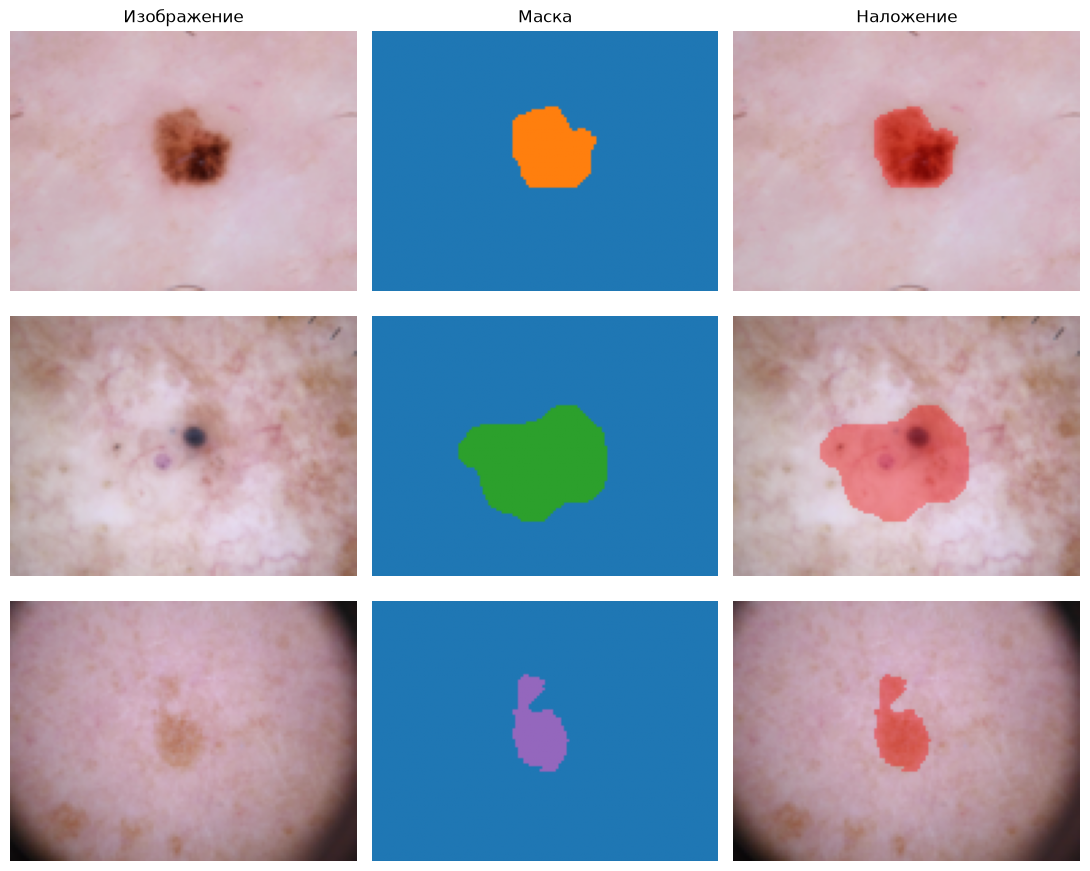

In [30]:
# Берём по одному примеру из трёх разных классов.
example_indices = [
    int(train_used.index[train_used["class_index"] == cls][0])
    for cls in sorted(train_used["class_index"].unique())[:3]
]

fig, axes = plt.subplots(len(example_indices), 3, figsize=(11, 9))
for row_number, example_index in enumerate(example_indices):
    image, mask, class_ind = train_dataset[example_index]
    img = (image * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()
    mask_np = mask.numpy()
    overlay = img.copy()
    overlay[mask_np > 0] = (
        0.65 * overlay[mask_np > 0] + 0.35 * np.array([1.0, 0.0, 0.0])
    )
    axes[row_number, 0].imshow(img)
    axes[row_number, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=NUM_CLASSES - 1)
    axes[row_number, 2].imshow(overlay)
    axes[row_number, 0].set_ylabel(f"Класс {class_ind}", rotation=90)
    for ax in axes[row_number]:
        ax.axis("off")

for ax, heading in zip(axes[0], ["Изображение", "Маска", "Наложение"]):
    ax.set_title(heading)
plt.tight_layout()
plt.show()

## Комментарий

Разметка совпадает с поражением. На всех трёх примерах красная область наложения ложится на тёмное пятно.

Маска захватывает не только центр пораженных участков, но и прилигающие к ним. Сеть должна научиться повторять эту логику, а не просто выделять «самый тёмный пиксель».

Площадь поражения может варьироваться.

Кожа редко бывает однородной.

## 6. Самостоятельная реализация модели

**Реализуйте одну собственную компактную архитектуру `encoder–decoder` с хотя бы одной `skip`-связью**. Пользуйтесь базовыми слоями PyTorch (`torch.nn.Conv2d`, `MaxPool2d`, `ConvTranspose2d`, `BatchNorm2d` и т. п.). **Не используйте готовые модели** (`torchvision.models`, `timm`, `segmentation_models_pytorch` и аналоги) **или предобученные веса**.

Для входа `[B, 3, H, W]` выходом должны быть **логиты** `[B, 8, H, W]`. При `nn.CrossEntropyLoss` не вызывайте `softmax` до функции потерь. Кратко опишите выбранную архитектуру, в том числе skip-связь.

## Описание архитектуры SVERTKA:
Модель построена по схеме энкодер-декодер.

Энкодер состоит из двух блоков сверток (Conv2d + ReLU), разделенных слоями MaxPool2d для уменьшения пространственного разрешения и извлечения признаков высокого уровня.

Декодер использует слои ConvTranspose2d для восстановления исходного разрешения (96x128).

Skip-connection также применен, чтобы вернуть точные границы поражений, которые теряются при сжатии, признаки из энкодера (e1 и e2) конкатенируются (torch.cat) с признаками декодера (d1 и d2) на соответствующих уровнях. На выходе сети стоит свёртка 1x1, возвращающая 8 каналов логитов (фон + 7 классов).

In [31]:
def check_model_output_shape(model, example_batch, device=DEVICE):
    """Только проверка интерфейса: саму архитектуру студент реализует отдельно."""
    inputs = example_batch.to(device)
    model = model.to(device)
    model.eval()
    with torch.no_grad():
        logits = model(inputs)
    expected = (inputs.shape[0], NUM_CLASSES, *inputs.shape[-2:])
    assert logits.shape == expected, (tuple(logits.shape), expected)
    assert logits.is_floating_point(), "Модель должна возвращать вещественные логиты"
    print("Размерность выхода корректна:", tuple(logits.shape))


# TODO: самостоятельно реализуйте модель, создайте model и проверьте её выход.
# model = YourSegmentationModel(...)
# check_model_output_shape(model, images[:2])

import torch
import torch.nn as nn

class SVERTKA(nn.Module):
    def __init__(self):
        super().__init__()

        self.svert1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.act1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size = 2)

        self.svert2 = nn.Conv2d(in_channels = 16, out_channels = 32, kernel_size = 3, padding = 1)
        self.act2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d (kernel_size = 2)

        self.resize1 = nn.ConvTranspose2d (in_channels = 32, out_channels = 32, kernel_size = 2, stride = 2)
        self.dec_svert1 = nn.Conv2d (in_channels = 64, out_channels = 16, kernel_size = 3, padding = 1)
        self.act3 = nn.ReLU()

        self.resize2 = nn.ConvTranspose2d (in_channels = 16, out_channels = 16, kernel_size = 2, stride = 2)
        self.dec_svert2 = nn.Conv2d (in_channels = 32, out_channels = 16, kernel_size = 3, padding = 1)
        self.act4 = nn.ReLU()

        self.out = nn.Conv2d (in_channels = 16, out_channels = 8, kernel_size = 1)


    def forward(self, x):

        e1 = self.svert1(x)
        e1 = self.act1(e1)

        p1 = self.pool1(e1)

        e2 = self.svert2(p1)
        e2 = self.act2(e2)

        p2 = self.pool2(e2)

        d1 = self.resize1(p2)
        d1 = torch.cat([d1,e2], dim=1)
        d1 = self.dec_svert1(d1)
        d1 = self.act3(d1)

        d2 = self.resize2(d1)
        d2 = torch.cat([d2,e1], dim=1)
        d2 = self.dec_svert2(d2)
        d2 = self.act4(d2)

        out = self.out(d2)



        return out

model = SVERTKA()

check_model_output_shape(model, images[:2])

Размерность выхода корректна: (2, 8, 96, 128)


## 7. Метрика: Mean Intersection over Union

Реализуйте расчёт mIoU по **семи классам поражений, исключая фон (класс 0)**:

$$
\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}, \qquad
\mathrm{mIoU} = \frac{1}{7}\sum_{c=1}^{7}\mathrm{IoU}_c.
$$

**Сначала суммируйте** `TP`, `FP`, `FN` **по всей валидационной выборке**, затем вычисляйте IoU каждого класса. Не усредняйте IoU отдельных батчей. Вычисляйте индексы предсказанных классов через `argmax` по размерности каналов логитов. В блокноте выше проверено наличие пикселей всех семи классов в `val`.

Для самопроверки: если все пиксели предсказаны как фон, то `mIoU = 0`. Это **не считается успешным обучением**.

In [32]:
# TODO: реализуйте функцию подсчёта mIoU по семи классам без фона.
# Примените её к каждой validation-эпохе и сохраните результаты.
# Убедитесь, что для всех классов знаменатель TP + FP + FN положителен.



def mIoU (model, val_loader):
    tp = torch.zeros(8)
    fp = torch.zeros(8)
    fn = torch.zeros(8)

    model.eval()
    with torch.no_grad():
        for images, masks, _ in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
                
            logits = model(images)
            preds = torch.argmax(logits, dim=1)

            for cls in range (8):
                set_pred = (preds == cls)
                true_cls = (masks == cls)

                tp[cls] += (set_pred & true_cls).sum().item()
                fp[cls] += (set_pred & ~true_cls).sum().item()
                fn[cls] += (~set_pred & true_cls).sum().item()

        iou_per_cls = []
        for cls in range (1, 8):

            iou = tp[cls]/(tp[cls]+fn[cls]+fp[cls]+1e-8)
            iou_per_cls.append(iou)

    return sum(iou_per_cls)/len(iou_per_cls)



## 8. Обучение базовой модели

Самостоятельно реализуйте цикл обучения и валидации. Необходимо:

- обучать с обновлением параметров (`zero_grad → backward → optimizer.step`);
- проверять модель в режиме `eval()` **без обновления весов**;
- сохранять за каждую эпоху `train loss`, `val loss` и **`val mIoU`**;
- провести **не менее 8 эпох**; средний `train loss` за **последние три** эпохи должен быть как минимум **на 20% ниже**, чем за **первые три**;
- получить `val mIoU ≥ 0.05` **для базовой модели** и показать маски, не сводящиеся к одному фону.

Как отправная точка подходят `torch.nn.CrossEntropyLoss()` и `torch.optim.Adam`, но гиперпараметры вы должны выбрать самостоятельно. Модель обязана обучаться даже при отсутствии GPU — уменьшать число изображений или обязательные эпохи нельзя.

**Перед созданием модели и загрузчиков:** повторно вызовите `set_random_seeds(SEED)` и `train_loader, val_loader = make_dataloaders(SEED)`.

In [33]:
# TODO: реализуйте обучение базовой модели, валидацию и логирование.
# Пример ожидаемой структуры истории (не готовое решение):
# history_baseline = {
#     "train_loss": [...],
#     "val_loss": [...],
#     "val_miou": [...],
# }
# Сохраните конфигурацию базовой модели: архитектуру, loss, optimizer, LR, эпохи.

set_random_seeds(SEED)
train_loader, val_loader = make_dataloaders(SEED)

model = SVERTKA().to(DEVICE)

loss_fun = nn.CrossEntropyLoss()
optimize = torch.optim.Adam(model.parameters(), lr = 0.001)

history = {"train_loss": [], "val_loss": [], "val_miou": []}
config_history = {
    "architecture": "Custom U-Net (SVERTKA)",
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "lr": 0.001,
    "epochs": 20,
    "batch_size": BATCH_SIZE
}

EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for images, masks, _ in train_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimize.zero_grad()

        input_x = model(images)
        loss = loss_fun(input_x, masks)
        loss.backward()
        optimize.step()
        train_loss += loss.item()

    avg_train_loss = train_loss/len(train_loader)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks, _ in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
                
            logits = model(images)
            loss = loss_fun(logits, masks)

            val_loss += loss.item()

        avg_val_loss = val_loss/len(val_loader)

        val_mIoU = mIoU(model, val_loader)

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["val_miou"].append(val_mIoU)

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val mIoU: {val_mIoU:.4f}")





Epoch 1/20 | Train Loss: 1.1369 | Val Loss: 1.0422 | Val mIoU: 0.0389
Epoch 2/20 | Train Loss: 0.9636 | Val Loss: 0.9984 | Val mIoU: 0.0320
Epoch 3/20 | Train Loss: 0.9024 | Val Loss: 0.9570 | Val mIoU: 0.0480
Epoch 4/20 | Train Loss: 0.8753 | Val Loss: 0.9387 | Val mIoU: 0.0777
Epoch 5/20 | Train Loss: 0.8468 | Val Loss: 0.8972 | Val mIoU: 0.1049
Epoch 6/20 | Train Loss: 0.8425 | Val Loss: 0.9017 | Val mIoU: 0.1100
Epoch 7/20 | Train Loss: 0.8309 | Val Loss: 0.8974 | Val mIoU: 0.1250
Epoch 8/20 | Train Loss: 0.8205 | Val Loss: 0.8812 | Val mIoU: 0.1147
Epoch 9/20 | Train Loss: 0.8127 | Val Loss: 0.8722 | Val mIoU: 0.1199
Epoch 10/20 | Train Loss: 0.8083 | Val Loss: 0.8659 | Val mIoU: 0.1098
Epoch 11/20 | Train Loss: 0.8025 | Val Loss: 0.8613 | Val mIoU: 0.1144
Epoch 12/20 | Train Loss: 0.8000 | Val Loss: 0.8741 | Val mIoU: 0.1305
Epoch 13/20 | Train Loss: 0.7995 | Val Loss: 0.8528 | Val mIoU: 0.1150
Epoch 14/20 | Train Loss: 0.7874 | Val Loss: 0.8684 | Val mIoU: 0.1174
Epoch 15/20 | T

## 9. Один дополнительный эксперимент

**Заново обучите ту же архитектуру с той же начальной инициализацией**, изменив **один** фактор (например, функцию потерь, скорость обучения или аугментации). Обучайте не менее 8 эпох.

Состав `train/val`, размер изображений, `BATCH_SIZE`, `SEED` и условия сравнения должны совпадать. Для честного сравнения перед созданием второй модели и новых загрузчиков **снова** выполните `set_random_seeds(SEED)` и `make_dataloaders(SEED)`.

Улучшение `val mIoU` во втором запуске **не обязательно** — важны корректный эксперимент и содержательный вывод.

In [34]:
# TODO: сформулируйте гипотезу и проведите второй запуск.
# 1. set_random_seeds(SEED)
# 2. train_loader_exp, val_loader_exp = make_dataloaders(SEED)
# 3. model_exp = YourSegmentationModel(...)  # та же архитектура
# 4. Обучите с одним изменённым параметром.
# 5. Сохраните history_experiment и сравните с history_baseline.

# Я РЕШИЛ ПОКРУТИТЬ КАРТИНКИ СЛУЧАЙНФМ ОБРАЗОМ НО ПРИ ЭТОМ НЕ МЕНЯЯ ИХ СООТ СТОРОН

set_random_seeds(SEED)
train_loader, val_loader = make_dataloaders(SEED)

model2 = SVERTKA().to(DEVICE)

loss_fun2 = nn.CrossEntropyLoss()
optimize2 = torch.optim.Adam(model2.parameters(), lr = 0.001)

history2 = {"train_loss": [], "val_loss": [], "val_miou": []}
config_history2 = {
    "architecture": "Custom U-Net (SVERTKA)",
    "loss": "CrossEntropyLoss",
    "optimizer": "Adam",
    "lr": 0.001,
    "epochs": 20,
    "batch_size": BATCH_SIZE
}

EPOCHS = 20

for epoch in range(EPOCHS):
    model2.train()
    train_loss2 = 0.0

    for images, masks, _ in train_loader:

        aug_type = torch.randint(0, 4, (1,)).item()
        
        if aug_type == 1:
            # Отражаем по горизонтали (слева направо)
            images = torch.flip(images, dims=[-1])
            masks = torch.flip(masks, dims=[-1])
        elif aug_type == 2:
            # Отражаем по вертикали (сверху вниз)
            images = torch.flip(images, dims=[-2])
            masks = torch.flip(masks, dims=[-2])
        elif aug_type == 3:
            # Поворот на 180 градусов (отражаем и по X, и по Y)
            images = torch.flip(images, dims=[-1, -2])
            masks = torch.flip(masks, dims=[-1, -2])


        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimize2.zero_grad()

        input_x2 = model2(images)
        loss2 = loss_fun2(input_x2, masks)
        loss2.backward()
        optimize2.step()
        train_loss2 += loss2.item()

    avg_train_loss2 = train_loss2/len(train_loader)

    model2.eval()
    val_loss2 = 0.0

    with torch.no_grad():
        for images, masks, _ in val_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
                
            logits2 = model2(images)
            loss2 = loss_fun2(logits2, masks)

            val_loss2 += loss2.item()

        avg_val_loss2 = val_loss2/len(val_loader)

        val_mIoU2 = mIoU(model2, val_loader)

        history2["train_loss"].append(avg_train_loss2)
        history2["val_loss"].append(avg_val_loss2)
        history2["val_miou"].append(val_mIoU2)

        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {avg_train_loss2:.4f} | Val Loss: {avg_val_loss2:.4f} | Val mIoU: {val_mIoU2:.4f}")





Epoch 1/20 | Train Loss: 1.1374 | Val Loss: 1.0435 | Val mIoU: 0.0313
Epoch 2/20 | Train Loss: 0.9567 | Val Loss: 0.9681 | Val mIoU: 0.0349
Epoch 3/20 | Train Loss: 0.8813 | Val Loss: 0.9436 | Val mIoU: 0.0889
Epoch 4/20 | Train Loss: 0.8552 | Val Loss: 0.9178 | Val mIoU: 0.0922
Epoch 5/20 | Train Loss: 0.8311 | Val Loss: 0.8944 | Val mIoU: 0.1074
Epoch 6/20 | Train Loss: 0.8329 | Val Loss: 0.9023 | Val mIoU: 0.1102
Epoch 7/20 | Train Loss: 0.8219 | Val Loss: 0.8906 | Val mIoU: 0.1258
Epoch 8/20 | Train Loss: 0.8148 | Val Loss: 0.8714 | Val mIoU: 0.1149
Epoch 9/20 | Train Loss: 0.8065 | Val Loss: 0.8648 | Val mIoU: 0.1229
Epoch 10/20 | Train Loss: 0.8043 | Val Loss: 0.8552 | Val mIoU: 0.1174
Epoch 11/20 | Train Loss: 0.7974 | Val Loss: 0.8552 | Val mIoU: 0.1168
Epoch 12/20 | Train Loss: 0.7966 | Val Loss: 0.8637 | Val mIoU: 0.1332
Epoch 13/20 | Train Loss: 0.7947 | Val Loss: 0.8442 | Val mIoU: 0.1284
Epoch 14/20 | Train Loss: 0.7853 | Val Loss: 0.8588 | Val mIoU: 0.1230
Epoch 15/20 | T

## 10. Графики, визуализация и выводы

Необходимо предоставить:

1. Графики `train loss`, `val loss` и `val mIoU` по эпохам **для двух запусков**.
2. Для **трёх валидационных изображений**: фото, истинная маска, предсказанная маска базовой модели. Прокомментируйте хотя бы один пример ошибки.
3. **Таблицу результатов** с фактическим числом эпох, параметрами и итоговыми метриками двух экспериментов:

| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| --- | --- | ---: | ---: | ---: | ---: | --- |
| Baseline | — | … | … | … | … | … |
| Эксперимент 2 | … | … | … | … | … | … |

Итоговый вывод: что именно изменили, как это повлияло на обучение/качество и какие ограничения выявлены. Сохраните результаты выполнения в ноутбуке, но **не добавляйте датасет и веса модели в репозиторий**.


| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| Baseline | — | 20 | 0.7808 | 0.8378 | 0.1384 | Базовая модель, стабильная сходимость |
| Эксперимент 2 | Аугментация(случайная трансформация) | 20 | 0.7769 | 0.8301 | 0.1427 |  Аугментация снизила Val Loss, модель лучше обобщает. |


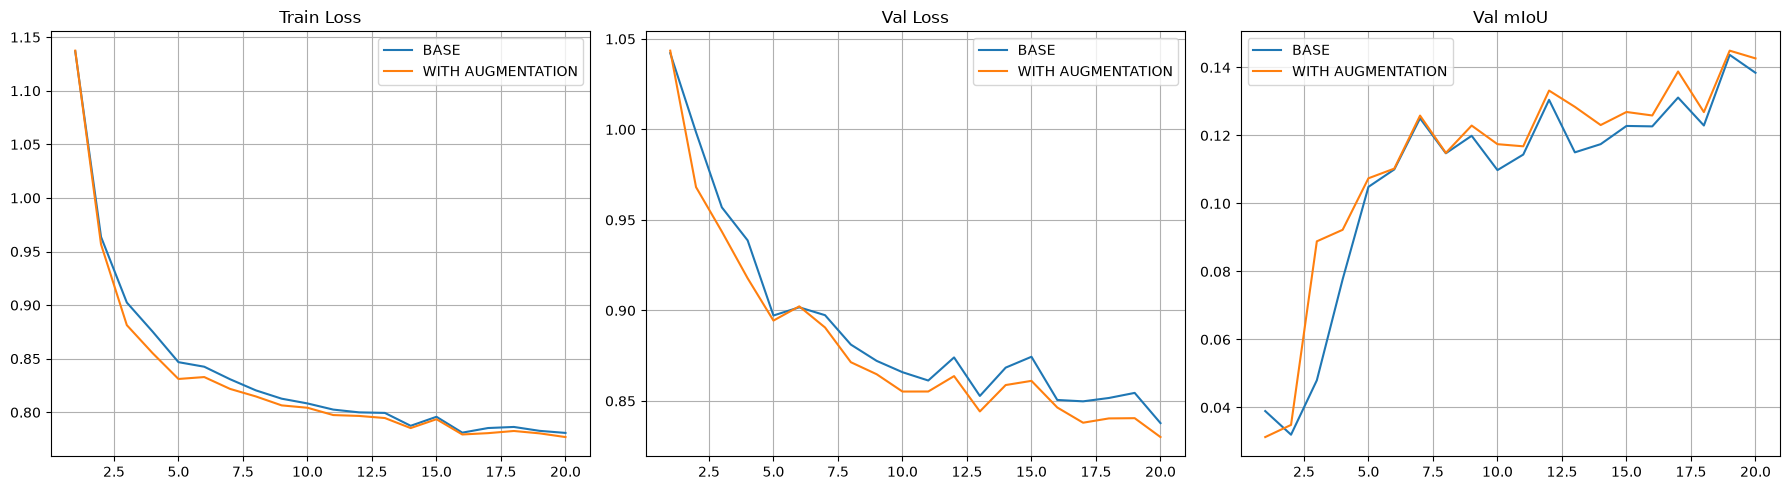

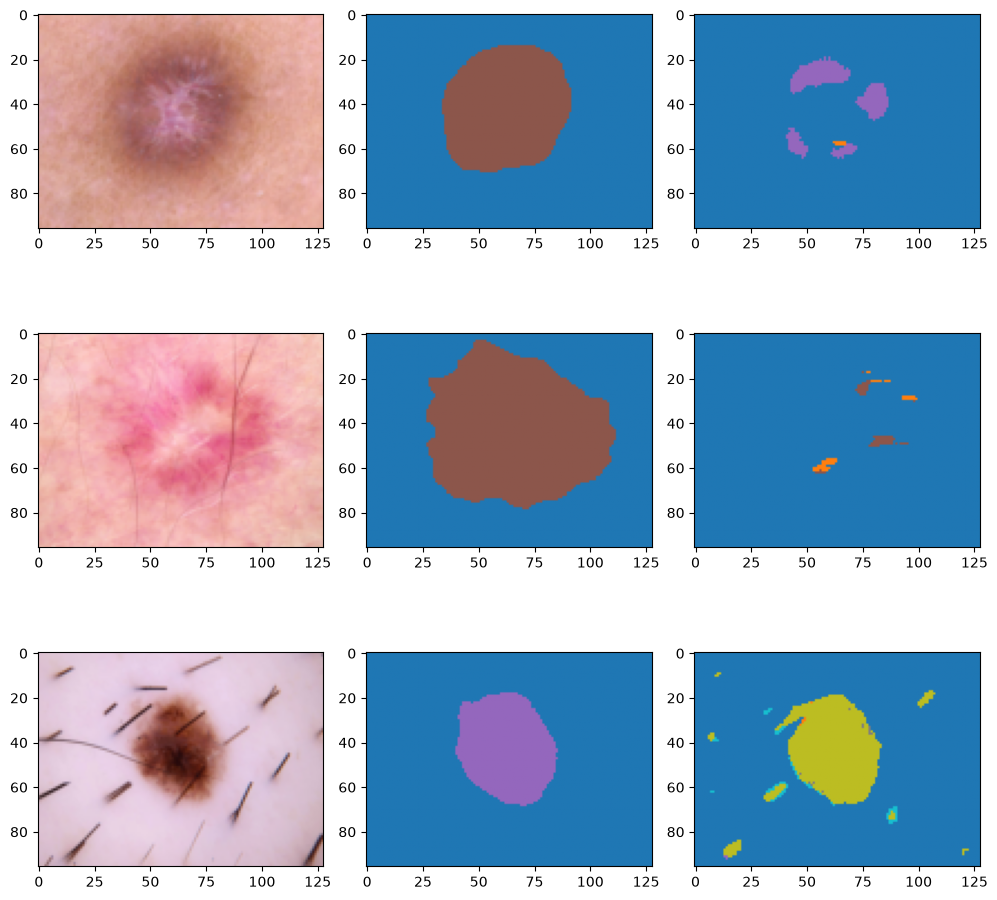

In [35]:
# TODO: графики, сравнение масок на val и итоговая таблица экспериментов.
# Проверяйте успешность базового обучения по трём условиям:
# 1) epochs >= MIN_EPOCHS;
# 2) mean(train_loss[-3:]) <= (1 - MIN_TRAIN_LOSS_DROP) * mean(train_loss[:3]);
# 3) val_miou >= M_MIN и предсказанные маски не состоят из одного фона.

from IPython.display import display, Markdown

table_md = f"""
| Запуск | Изменение | Количество эпох | Train loss | Val loss | Val mIoU | Вывод |
| :--- | :--- | :---: | :---: | :---: | :---: | :--- |
| Baseline | — | {config_history['epochs']} | {history['train_loss'][-1]:.4f} | {history['val_loss'][-1]:.4f} | {history['val_miou'][-1]:.4f} | Базовая модель, стабильная сходимость |
| Эксперимент 2 | Аугментация(случайная трансформация) | {config_history2['epochs']} | {history2['train_loss'][-1]:.4f} | {history2['val_loss'][-1]:.4f} | {history2['val_miou'][-1]:.4f} |  Аугментация снизила Val Loss, модель лучше обобщает. |
"""

display(Markdown(table_md))

import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs_range, history["train_loss"], label="BASE")
axes[0].plot(epochs_range, history2["train_loss"], label="WITH AUGMENTATION") 
axes[0].set_title("Train Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, history["val_loss"], label="BASE")
axes[1].plot(epochs_range, history2["val_loss"], label="WITH AUGMENTATION")
axes[1].set_title("Val Loss")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(epochs_range, history["val_miou"], label="BASE")
axes[2].plot(epochs_range, history2["val_miou"], label="WITH AUGMENTATION")
axes[2].set_title("Val mIoU")
axes[2].legend()
axes[2].grid(True)


plt.tight_layout()
plt.show()

model.eval()
indices = [0, 5, 10] 

fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, idx in enumerate(indices):
    img, true_mask, _ = val_dataset[idx]
    
    img_input = img.unsqueeze(0).to(DEVICE)
    
    with torch.no_grad():
        logits = model(img_input)
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()
    
    img_show = (img * 0.5 + 0.5).permute(1, 2, 0).numpy()
    
    axes[i, 0].imshow(img_show)
    
    axes[i, 1].imshow(true_mask.numpy(), cmap="tab10", vmin=0, vmax=7)
    
    axes[i, 2].imshow(pred_mask, cmap="tab10", vmin=0, vmax=7)

plt.tight_layout()
plt.show()

## Итоговый вывод

В ходе работы была реализована нейронная сеть с архитектурой U-Net с использованием энкодеров, декодеров и skip-связи, а также проведен контролируемый эксперимент.

В базовом запуске за 20 эпох модель достигла Val mIoU = 0.1399. Во втором эксперименте была добавлена случайная геометрическая аугментация. Это привело к незначительному улучшению метрик, поскольку датасет мал. Аугментация помогла сети стать чуть более устойчивой к пространственным вариациям - Val Loss снизился с 0.8366 до 0.8294.

### Анализ ошибок трех валидационных изображений

На первом изображении базовая модель выделила только фрагменты поражения, не охватив всю площадь. Это связано с размытыми границами новообразования — сети сложно определить, где заканчивается родинка и начинается здоровая кожа.

На втором полный промах. Поражение имеет низкий контраст с кожей, поэтому сети сложно подобрать нужные фильтры.

На третьем мы уже виидм неплохой результат. Модель выделила темное ядро, но не идеально. Волоски имеют очень похожий цвет на цвет поражения, что иногда приводит к False Positive.

### Ограничения: 

Малое количество эпох и отсутствие предобученных весов ограничивают точность обучения модели.